In [1]:
from IPython.display import HTML, display
COMPACT_PRINT_CSS = "<style>\n@page { size: A4 portrait; margin: 11mm 12mm 12mm 12mm; }\n@media print {\n  :root { --jp-content-font-family: Arial, sans-serif; }\n  body { background: white !important; }\n  html, body { margin: 0 !important; padding: 0 !important; width: auto !important; }\n  body, .jp-RenderedHTMLCommon { font-family: Arial, sans-serif !important;\n    font-size: 9.6pt !important; line-height: 1.23 !important; color: #111 !important; }\n  .jp-Notebook { padding: 0 !important; margin: 0 !important; width: auto !important;\n    max-width: none !important; min-width: 0 !important; }\n  main, .jp-Cell, .jp-Cell-inputWrapper, .jp-Cell-outputWrapper,\n  .jp-InputArea, .jp-OutputArea, .jp-OutputArea-child, .jp-InputArea-editor,\n  .jp-RenderedHTMLCommon, .jp-RenderedText { min-width: 0 !important;\n    max-width: 100% !important; }\n  .jp-Cell { padding: 0 !important; margin: 0 0 4pt !important;\n    break-inside: auto !important; }\n  .jp-Cell-inputWrapper, .jp-Cell-outputWrapper { margin: 0 !important;\n    padding: 0 !important; }\n  .jp-InputPrompt, .jp-OutputPrompt, .jp-Collapser { display: none !important; }\n  .jp-RenderedMarkdown { padding: 0 !important; }\n  .jp-RenderedMarkdown h1 { font-size: 15pt !important; line-height: 1.14 !important;\n    margin: 0 0 6pt !important; break-after: avoid !important; }\n  .jp-RenderedMarkdown h2 { font-size: 12pt !important; line-height: 1.18 !important;\n    margin: 8pt 0 4pt !important; break-after: avoid !important; }\n  .jp-RenderedMarkdown p { margin: 3pt 0 5pt !important; orphans: 3; widows: 3; }\n  .jp-RenderedMarkdown a { color: #155d8b !important; text-decoration: none; }\n  .jp-InputArea-editor { border: 0.4pt solid #d7dce2 !important;\n    background: #f6f7f9 !important; border-radius: 0 !important; padding: 0 !important; }\n  .highlight { padding: 0 !important; margin: 0 !important; background: transparent !important; }\n  .highlight pre { font-family: 'DejaVu Sans Mono', Consolas, monospace !important;\n    font-size: 8.2pt !important; line-height: 1.17 !important; padding: 5pt 6pt !important;\n    margin: 0 !important; white-space: pre-wrap !important; overflow-wrap: anywhere !important;\n    word-break: normal !important; tab-size: 4; }\n  pre, code, .cm-editor, .jp-InputArea-editor { overflow: visible !important;\n    text-overflow: clip !important; max-height: none !important; }\n  .jp-RenderedText pre { font-family: 'DejaVu Sans Mono', Consolas, monospace !important;\n    font-size: 8.1pt !important; line-height: 1.2 !important; padding: 2pt 0 !important;\n    margin: 0 !important; white-space: pre-wrap !important; overflow-wrap: anywhere !important; }\n  .jp-RenderedImage { padding: 2pt 0 !important; text-align: center !important;\n    break-inside: avoid !important; }\n  .jp-RenderedImage img { display: block !important; width: 100% !important;\n    max-width: 100% !important; height: auto !important; margin: 0 auto !important;\n    break-inside: avoid !important; }\n  .jp-OutputArea-child { padding: 0 !important; break-inside: avoid !important; }\n  .jp-CodeCell[id$='-hidden'] > .jp-Cell-inputWrapper { display: none !important; }\n  .jp-CodeCell[id$='-hidden']:not(:has(.jp-Cell-outputWrapper)) { display: none !important; }\n  [id='cell-id=report-print-style'] { display: none !important; }\n  .anchor-link { display: none !important; }\n  mjx-container { font-size: 100% !important; }\n}\n</style>"
display(HTML(COMPACT_PRINT_CSS))

# EN3160 Assignment 1 - Intensity Transformations and Neighborhood Filtering
**D. P. Heshan Ranasinghe | Index: 230521E | 
[GitHub](https://github.com/DPHeshanRanasinghe/EN3160-Image-Processing-and-Machine-Vision)**

In [2]:
from pathlib import Path
import cv2 # type: ignore
import matplotlib.pyplot as plt # type: ignore
import numpy as np # type: ignore
IMAGE_DIR = Path("images")
plt.rcParams.update({"font.size": 8, "figure.dpi": 130})

## 1. Piecewise intensity transformation
The vertical lines in Fig. 1a are jumps in the transformation, so the input values 50 and 150 appear twice. I used linear interpolation only between points with different input values.

In [3]:
def intensity_transform(im, breakpoints):
    breakpoints = np.asarray(breakpoints, dtype=float)
    transformed = np.zeros(im.shape, dtype=float)
    for (x1, y1), (x2, y2) in zip(breakpoints[:-1], breakpoints[1:]):
        if x1 == x2:                 # vertical jump
            continue
        mask = (im >= x1) & (im < x2)
        transformed[mask] = y1 + (im[mask] - x1) * (y2 - y1) / (x2 - x1)
    transformed[im == breakpoints[-1, 0]] = breakpoints[-1, 1]
    return np.clip(np.rint(transformed), 0, 255).astype(np.uint8)
# Points read directly from Fig. 1a (repeated x-values draw the jumps)
figure_breakpoints = np.array([
    [0, 0], [50, 50], [50, 100], [150, 255], [150, 150], [255, 255]
])
# Continuous points chosen after observing the banding in Fig. 1a
chosen_breakpoints = np.array([
    [0, 0], [50, 75], [150, 200], [255, 255]
])

In [4]:
image = cv2.imread(str(IMAGE_DIR / "q01_portrait_intensity_transform.jpeg"), cv2.IMREAD_GRAYSCALE)
if image is None:
    raise FileNotFoundError("Question 1 image was not found")
figure_result = intensity_transform(image, figure_breakpoints)
chosen_result = intensity_transform(image, chosen_breakpoints)

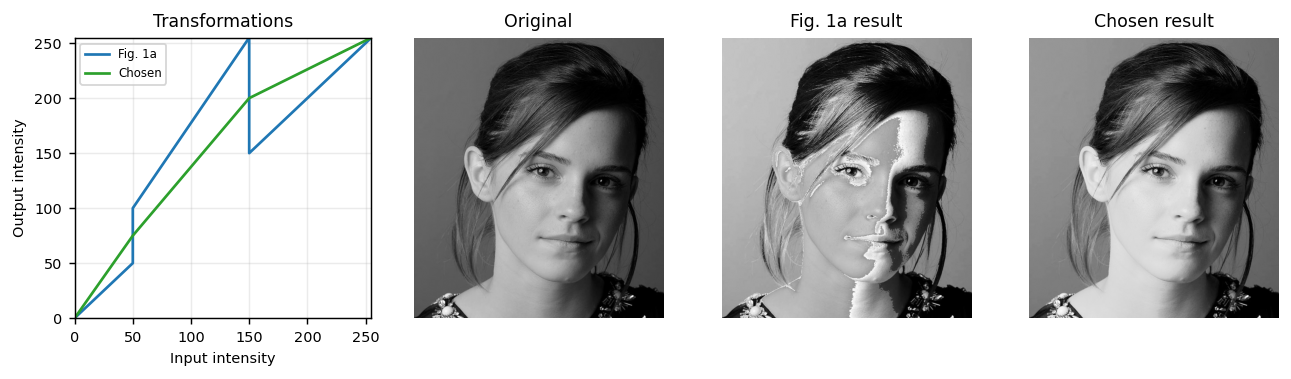

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8), constrained_layout=True)
axes[0].plot(figure_breakpoints[:, 0], figure_breakpoints[:, 1], color="tab:blue", label="Fig. 1a")
axes[0].plot(chosen_breakpoints[:, 0], chosen_breakpoints[:, 1], color="tab:green", label="Chosen")
axes[0].set(xlabel="Input intensity", ylabel="Output intensity", xlim=(0, 255), ylim=(0, 255), title="Transformations")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=6.5)
for ax, result, title in zip(axes[1:], [image, figure_result, chosen_result], ["Original", "Fig. 1a result", "Chosen result"]):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

In [6]:
print(f"Chosen result - mean: {image.mean():.1f} -> {chosen_result.mean():.1f}, standard deviation: {image.std():.1f} -> {chosen_result.std():.1f}")

Chosen result - mean: 92.3 -> 121.7, standard deviation: 56.1 -> 65.9


**Interpretation and discussion**

The transformation given in the question strongly increases intensities between 50 and 149. However, it has sudden jumps at the breakpoints. These jumps can map pixels with very similar original intensities to very different output intensities, which explains the unnatural bright bands visible on the face.

I selected the continuous breakpoints $(0,0)$, $(50,75)$, $(150,200)$ and $(255,255)$ to obtain a smoother result. The selected curve is above the identity line for intermediate intensities, so it brightens these pixels. It also compresses the brightest intensity range, so already bright areas receive a smaller change.

The mean intensity increased from **92.3 to 121.7**, showing that the image became brighter overall. The standard deviation increased from **56.1 to 65.9**, showing a wider overall spread of intensity values. Together with the side-by-side images, these results support my choice of transformation. However, a higher standard deviation alone does not guarantee that every region has better contrast, so the visual comparison is also necessary.


## 2. Accentuating white matter and gray matter
White matter and gray matter are tissue types, not simply white and gray pixels. In this proton-density image, white matter is mainly in the lower tissue range (about 150-180), while gray matter is slightly brighter (about 180-210). Separate piecewise transformations were used to brighten each range.

In [7]:
brain = cv2.imread(str(IMAGE_DIR / "q02_brain_proton_density.jpeg"), cv2.IMREAD_GRAYSCALE)
white_matter_breakpoints = np.array([
    [0, 0], [150, 110], [150, 225], [180, 255], [180, 125], [255, 210]
])
gray_matter_breakpoints = np.array([
    [0, 0], [180, 120], [180, 225], [210, 255], [210, 140], [255, 210]
])
white_matter_result = intensity_transform(brain, white_matter_breakpoints)
gray_matter_result = intensity_transform(brain, gray_matter_breakpoints)

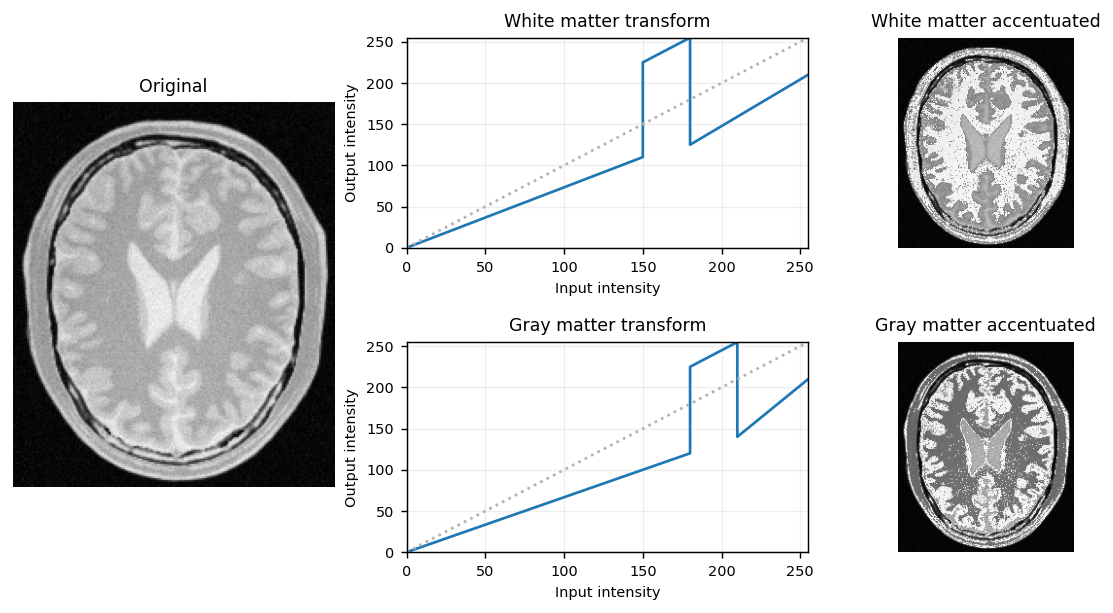

In [8]:
fig = plt.figure(figsize=(8.8, 4.6), constrained_layout=True)
grid = fig.add_gridspec(2, 3, width_ratios=[0.8, 1, 0.8])
original_ax = fig.add_subplot(grid[:, 0])
white_plot_ax, white_image_ax = fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[0, 2])
gray_plot_ax, gray_image_ax = fig.add_subplot(grid[1, 1]), fig.add_subplot(grid[1, 2])
original_ax.imshow(brain, cmap="gray", vmin=0, vmax=255)
original_ax.set_title("Original")
original_ax.axis("off")
for ax, points, title in [(white_plot_ax, white_matter_breakpoints, "White matter transform"), (gray_plot_ax, gray_matter_breakpoints, "Gray matter transform")]:
    ax.plot(points[:, 0], points[:, 1])
    ax.plot([0, 255], [0, 255], ":", color="0.7")
    ax.set(xlabel="Input intensity", ylabel="Output intensity", xlim=(0, 255), ylim=(0, 255), title=title)
    ax.grid(alpha=0.2)
for ax, result, title in [(white_image_ax, white_matter_result, "White matter accentuated"), (gray_image_ax, gray_matter_result, "Gray matter accentuated")]:
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Interpretation and discussion**

I used separate transformations to make the approximate white-matter and gray-matter intensity ranges stand out. For this image, I selected $150 \leq r < 180$ for white-matter enhancement and $180 \leq r < 210$ for gray-matter enhancement, where $r$ is the original pixel intensity.

The first transformation makes the selected inner brain regions brighter relative to surrounding regions. The second transformation makes the selected gray-matter structures more visible. This shows how a piecewise transformation can emphasise a particular intensity range.

Within each selected range, the transformation mainly adds a brightness offset. Therefore, the enhancement comes from making that range stand out against other intensities, rather than stretching differences between pixels inside the selected range.

A limitation is that different tissues and other structures can have overlapping intensity values. Some unwanted pixels are therefore enhanced as well. These transformations provide visual emphasis, but they do not produce exact tissue segmentation. The thresholds are specific to this image and may need adjustment for another image.


## 3. Gamma correction in the $L^*a^*b^*$ color space
Gamma correction was applied only to the lightness ($L$) plane using $L_{new}=255(L/255)^{\gamma}$. Values 0.5, 0.65 and 0.8 were compared, and **$\gamma=0.65$** was selected.

In [9]:
image_bgr = cv2.imread(str(IMAGE_DIR / "q03_white_dress_gamma_correction.jpeg"))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
L, a, b = cv2.split(lab)
gamma = 0.65
L_corrected = 255 * (L / 255.0) ** gamma
L_corrected = np.clip(L_corrected, 0, 255).astype(np.uint8)
corrected_lab = cv2.merge([L_corrected, a, b])
corrected_rgb = cv2.cvtColor(corrected_lab, cv2.COLOR_LAB2RGB)

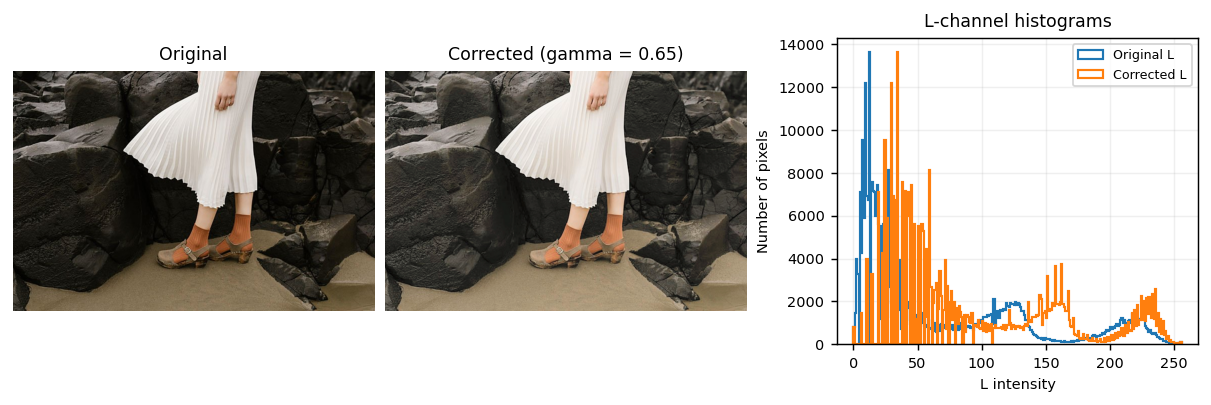

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.0), constrained_layout=True)
axes[0].imshow(image_rgb)
axes[0].set_title("Original")
axes[1].imshow(corrected_rgb)
axes[1].set_title(f"Corrected (gamma = {gamma})")
for ax in axes[:2]:
    ax.axis("off")
axes[2].hist(L.ravel(), bins=256, range=(0, 256),
             histtype="step", color="tab:blue", linewidth=1.2,
             label="Original L")
axes[2].hist(L_corrected.ravel(), bins=256, range=(0, 256),
             histtype="step", color="tab:orange", linewidth=1.2,
             label="Corrected L")
axes[2].set_xlabel("L intensity")
axes[2].set_ylabel("Number of pixels")
axes[2].set_title("L-channel histograms")
axes[2].legend(fontsize=7)
axes[2].grid(alpha=0.2)
plt.show()

In [11]:
print(f"Mean L: {L.mean():.1f} -> {L_corrected.mean():.1f}")

Mean L: 71.3 -> 98.6


**Interpretation and discussion**

I applied gamma correction to the lightness plane using $L_{\text{new}} = 255(L/255)^\gamma$ and selected **$\gamma = 0.65$**. With this equation, a gamma value below 1 increases intermediate lightness values, making darker parts of the image easier to see.

In the corrected image, the details in the dark rocks become clearer while the white dress remains bright. The mean of the stored 8-bit lightness values increased from **71.3 to 98.6**. The histogram also shifts towards higher lightness values, supporting the observed increase in brightness.

From my visual comparison, $\gamma = 0.5$ produced a washed-out appearance, while $\gamma = 0.8$ gave a smaller improvement. I therefore selected 0.65 as a balance between revealing shadow detail and keeping a natural appearance.

I kept the $a$ and $b$ channels unchanged, so the adjustment was made through lightness rather than by separately modifying the RGB channels. However, excessive brightening can still make the image look unnatural and may make noise in dark regions more noticeable.


## 4. Vibrance enhancement in HSV
The given transformation was applied only to the saturation plane with $\sigma=70$. Values $a=0.3$, $0.5$ and $0.7$ were compared, and **$a=0.5$** was selected.

In [12]:
q4_bgr = cv2.imread(str(IMAGE_DIR / "q04_spiderman_vibrance.jpeg"))
q4_rgb = cv2.cvtColor(q4_bgr, cv2.COLOR_BGR2RGB)
q4_hsv = cv2.cvtColor(q4_bgr, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(q4_hsv)
a_value, sigma = 0.5, 70
x = np.arange(256, dtype=float)
transform = np.minimum(x + a_value * 128 * np.exp(-((x - 128) ** 2) / (2 * sigma ** 2)), 255)
S_enhanced = np.rint(transform).astype(np.uint8)[S]
enhanced_hsv = cv2.merge([H, S_enhanced, V])
enhanced_rgb = cv2.cvtColor(enhanced_hsv, cv2.COLOR_HSV2RGB)

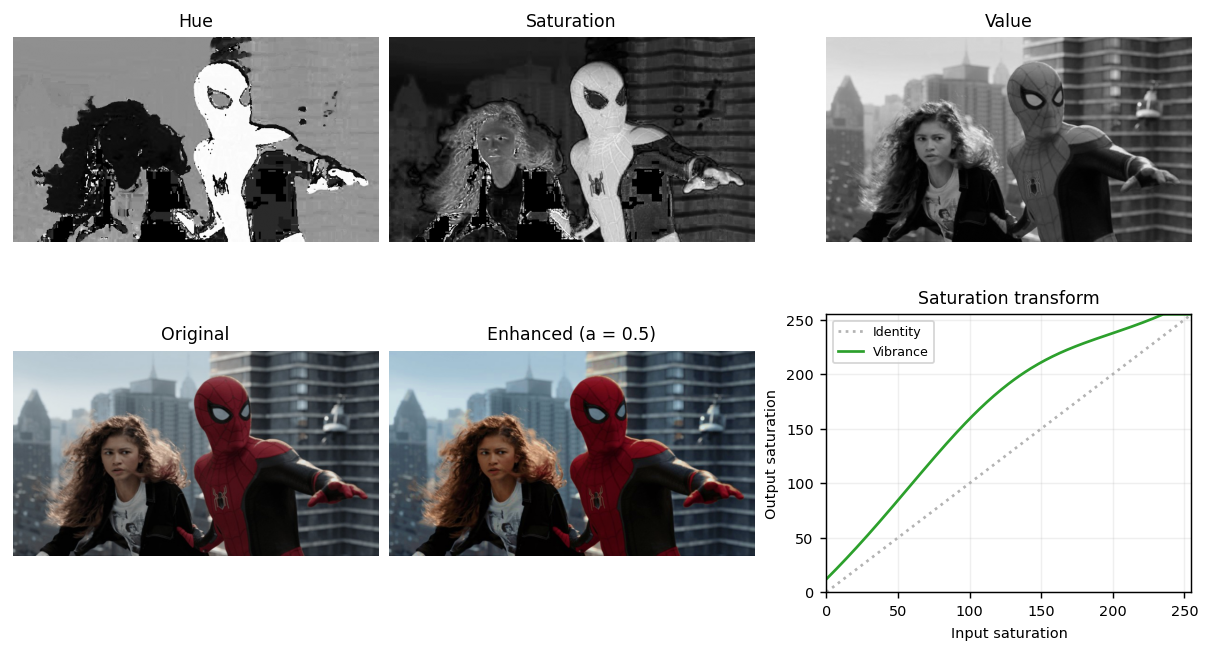

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(9.2, 5.0), constrained_layout=True)
for ax, plane, title, vmax in zip(axes[0], [H, S, V], ["Hue", "Saturation", "Value"], [179, 255, 255]):
    ax.imshow(plane, cmap="gray", vmin=0, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")
axes[1, 0].imshow(q4_rgb)
axes[1, 0].set_title("Original")
axes[1, 1].imshow(enhanced_rgb)
axes[1, 1].set_title(f"Enhanced (a = {a_value})")
for ax in axes[1, :2]:
    ax.axis("off")
axes[1, 2].plot(x, x, ":", color="0.7", label="Identity")
axes[1, 2].plot(x, transform, color="tab:green", label="Vibrance")
axes[1, 2].set(xlabel="Input saturation", ylabel="Output saturation", xlim=(0, 255), ylim=(0, 255), title="Saturation transform")
axes[1, 2].legend(fontsize=7)
axes[1, 2].grid(alpha=0.2)
plt.show()

In [14]:
print(f"Mean saturation: {S.mean():.1f} -> {S_enhanced.mean():.1f}")

Mean saturation: 62.1 -> 94.3


**Interpretation and discussion**

I applied the given transformation to the saturation channel using **$a = 0.5$** and **$\sigma = 70$**. Saturation describes how strong or vivid a colour appears. Increasing it makes colours less grey and more pronounced.

The transformation gives its largest added boost around a saturation value of 128. Therefore, it strongly enhances colours with moderate saturation. In my result, Spider-Man’s suit and the surrounding scene appear more vivid. The mean saturation increased from **62.1 to 94.3**, which supports this observation.

I selected $a = 0.5$ because $a = 0.3$ produced a weaker effect, while $a = 0.7$ made some colours look too strong. Increasing $a$ increases the saturation boost, and clipping at 255 prevents values from exceeding the available range.

The H and V channels were kept unchanged. However, this does not guarantee that perceived brightness remains identical. Another limitation is that the given formula also increases saturation slightly when the original saturation is zero. It can therefore introduce a small tint into neutral areas rather than keeping all grey pixels completely unchanged.


## 5. Histogram equalization
A custom histogram-equalization function was applied to improve the global contrast of Fig. 5.

In [15]:
def histogram_equalization(im):
    histogram = np.bincount(im.ravel(), minlength=256)
    cdf = histogram.cumsum()
    cdf_min = cdf[cdf > 0][0]
    if cdf_min == im.size:
        return im.copy()
    lut = np.round((cdf - cdf_min) * 255 / (im.size - cdf_min))
    lut = np.clip(lut, 0, 255).astype(np.uint8)
    return lut[im]
shells = cv2.imread(str(IMAGE_DIR / "q05_shells_histogram_equalization.tif"), cv2.IMREAD_GRAYSCALE)
equalized_shells = histogram_equalization(shells)

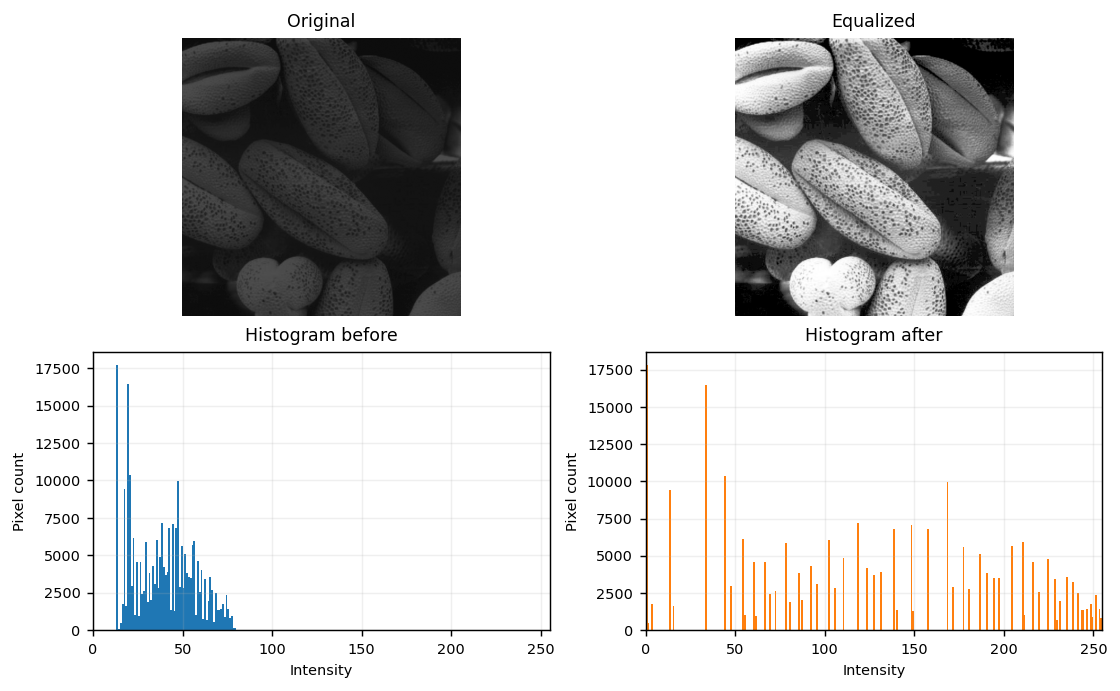

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(8.5, 5.2), constrained_layout=True)
axes[0, 0].imshow(shells, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 1].imshow(equalized_shells, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Equalized")
for ax in axes[0]:
    ax.axis("off")
axes[1, 0].hist(shells.ravel(), bins=256, range=(0, 256), color="tab:blue")
axes[1, 0].set_title("Histogram before")
axes[1, 1].hist(equalized_shells.ravel(), bins=256, range=(0, 256), color="tab:orange")
axes[1, 1].set_title("Histogram after")
for ax in axes[1]:
    ax.set(xlabel="Intensity", ylabel="Pixel count", xlim=(0, 255))
    ax.grid(alpha=0.2)
plt.show()

In [17]:
print(f"Intensity range: {shells.min()}-{shells.max()} -> {equalized_shells.min()}-{equalized_shells.max()}")

Intensity range: 13-83 -> 0-255


**Interpretation and discussion**

The original image uses a narrow, dark intensity range of **13–83**. Because many pixels have similar intensity values, some shell textures and boundaries are difficult to distinguish.

My histogram-equalization function uses the cumulative distribution function, or CDF, to create an intensity mapping. After equalization, the occupied intensity range extends from **0 to 255**. This gives the image a wider range of dark and bright values. In the result, shell textures and boundaries are easier to see, and the shells stand out more clearly from the background.

The output histogram is more spread out, but it is not perfectly flat. This is expected because the image contains discrete intensity levels. All pixels with the same original intensity receive the same new intensity, so the method cannot freely redistribute individual pixels into every output level.

The result shows an improvement in overall contrast for this image. However, histogram equalization uses one mapping for the whole image. It may therefore improve some regions more than others, and it can also make existing noise more visible.


## 6. Histogram equalization of the foreground
The saturation plane separates the coloured subject from the nearly grey background. Histogram equalization is then applied only to the foreground value intensities.

In [18]:
q6_bgr = cv2.imread(
    str(IMAGE_DIR / "q06_portrait_foreground_equalization.jpeg")
)
if q6_bgr is None:
    raise FileNotFoundError("Question 6 image was not found")
q6_rgb = cv2.cvtColor(q6_bgr, cv2.COLOR_BGR2RGB)
q6_hsv = cv2.cvtColor(q6_bgr, cv2.COLOR_BGR2HSV)
H6, S6, V6 = cv2.split(q6_hsv)
rough_mask = np.where((S6 > 20) | (V6 < 50), 255, 0).astype(np.uint8)
rough_mask = cv2.morphologyEx(
    rough_mask,
    cv2.MORPH_CLOSE,
    np.ones((9, 9), np.uint8)
)
contours, _ = cv2.findContours(rough_mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
if not contours:
    raise ValueError("No foreground was found. Check the thresholds.")
mask6 = np.zeros_like(S6)
cv2.drawContours(mask6,[max(contours, key=cv2.contourArea)],-1,255,cv2.FILLED)
# Extract the foreground value plane.
foreground_V = cv2.bitwise_and(V6, V6, mask=mask6)
fg6 = mask6 > 0
# Count only foreground pixels.
hist6 = np.bincount(
    foreground_V[fg6], minlength=256
)
cdf6 = np.cumsum(hist6)
cdf_min6 = cdf6[cdf6 > 0][0]
# Identity mapping handles a constant-intensity foreground.
lut6 = np.arange(256, dtype=np.uint8)
if cdf6[-1] > cdf_min6:
    lut6 = np.clip(np.rint(255.0 * (cdf6 - cdf_min6)/ (cdf6[-1] - cdf_min6)),0,255).astype(np.uint8)
# Change V only within the foreground.
V6_equalized = V6.copy()
V6_equalized[fg6] = lut6[V6[fg6]]
equalized_hsv = cv2.merge([H6, S6, V6_equalized])
equalized_rgb = cv2.cvtColor(equalized_hsv, cv2.COLOR_HSV2RGB)
equalized_foreground = cv2.bitwise_and(equalized_rgb, equalized_rgb, mask=mask6)
background = cv2.bitwise_and(q6_rgb,q6_rgb,mask=cv2.bitwise_not(mask6))
q6_result = cv2.add(equalized_foreground, background)

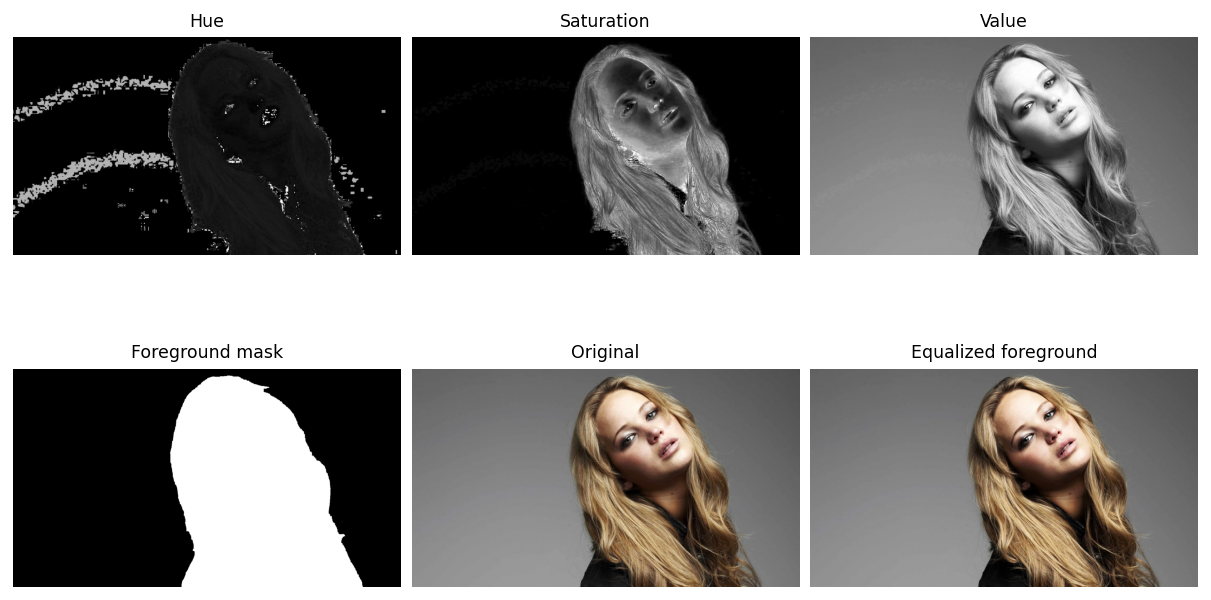

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(9.2, 5.1), constrained_layout=True)
for ax, plane, title in zip(axes[0], [H6, S6, V6], ["Hue", "Saturation", "Value"]):
    ax.imshow(plane, cmap="gray")
    ax.set_title(title)
axes[1, 0].imshow(mask6, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Foreground mask")
axes[1, 1].imshow(q6_rgb)
axes[1, 1].set_title("Original")
axes[1, 2].imshow(q6_result)
axes[1, 2].set_title("Equalized foreground")
for ax in axes.ravel():
    ax.axis("off")
plt.show()

In [20]:
print(f"Foreground value standard deviation: {V6[mask6 > 0].std():.1f} -> {lut6[V6][mask6 > 0].std():.1f}")

Foreground value standard deviation: 66.7 -> 73.6


**Interpretation and discussion**

I used the saturation channel to help separate the coloured subject from the nearly grey background. The condition $S > 20$ selects coloured regions, while $V < 50$ helps include dark foreground areas that may have low saturation. I then used morphological closing to close small gaps and filled the largest contour to obtain the final foreground mask.

I calculated the histogram using only pixels inside this mask. This is necessary because extracting the foreground creates black pixels outside the mask. Counting these artificial background zeros would change the CDF and produce an equalization mapping that does not represent the foreground alone. Genuine zero-valued pixels inside the foreground are still included.

After equalization, the standard deviation of the foreground V values increased from **66.7 to 73.6**. This indicates a wider spread of foreground brightness values and supports the stronger contrast visible in the result.

Only the foreground V values were changed, while H and S were retained. The final background was copied directly from the original RGB image, so its pixel values remained unchanged. The main limitation is mask accuracy: any background pixel incorrectly included in the foreground mask would also be equalized.


## 7. Sobel filtering
The horizontal and vertical Sobel responses are combined as $G=\sqrt{G_x^2+G_y^2}$. The result is computed using `filter2D`, a manual spatial correlation, and separable 1-D filters.

In [ ]:
q7_gray = cv2.imread(str(IMAGE_DIR / "q07_einstein_sobel.jpeg"), cv2.IMREAD_GRAYSCALE)
sobel_x = np.array([
    [ 1,  2,  1],
    [ 0,  0,  0],
    [-1, -2, -1]
], dtype=float)
sobel_y = sobel_x.T
# (a) OpenCV filter2D
gx_filter2d = cv2.filter2D(q7_gray, cv2.CV_64F, sobel_x, borderType=cv2.BORDER_REFLECT_101)
gy_filter2d = cv2.filter2D(q7_gray, cv2.CV_64F, sobel_y, borderType=cv2.BORDER_REFLECT_101)
# (b) Manual spatial filtering
def manual_filter2d(im, kernel):
    padded = np.pad(im.astype(float), 1, mode="reflect")
    result = np.zeros(im.shape, dtype=float)
    for row in range(im.shape[0]):
        for col in range(im.shape[1]):
            result[row, col] = np.sum(padded[row:row + 3, col:col + 3] * kernel)
    return result
gx_manual = manual_filter2d(q7_gray, sobel_x)
gy_manual = manual_filter2d(q7_gray, sobel_y)

# (c) Separable Sobel filters
smooth_row = np.array([[1, 2, 1]], dtype=np.float64)
derivative_row = np.array([[1, 0, -1]], dtype=np.float64)

smooth_col = smooth_row.T
derivative_col = derivative_row.T

border = cv2.BORDER_REFLECT_101
# Gx: smooth across columns, then differentiate across rows.
gx_separable = cv2.filter2D(
    cv2.filter2D(
        q7_gray, cv2.CV_64F, smooth_row, borderType=border
    ),
    cv2.CV_64F, derivative_col, borderType=border
)
# Gy: differentiate across columns, then smooth across rows.
gy_separable = cv2.filter2D(
    cv2.filter2D(
        q7_gray, cv2.CV_64F, derivative_row, borderType=border
    ),
    cv2.CV_64F, smooth_col, borderType=border
)

In [22]:
def show_magnitude(gx, gy):
    magnitude = np.hypot(gx, gy)
    return cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

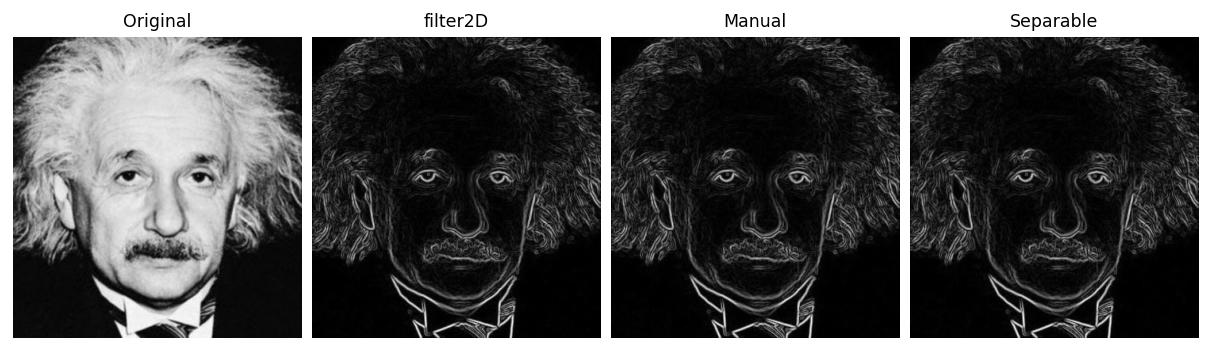

In [23]:
results7 = [q7_gray, show_magnitude(gx_filter2d, gy_filter2d),
            show_magnitude(gx_manual, gy_manual), show_magnitude(gx_separable, gy_separable)]
titles7 = ["Original", "filter2D", "Manual", "Separable"]
fig, axes = plt.subplots(1, 4, figsize=(9.2, 3.0), constrained_layout=True)
for ax, image, title in zip(axes, results7, titles7):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

In [24]:
manual_error = max(np.abs(gx_filter2d - gx_manual).max(), np.abs(gy_filter2d - gy_manual).max())
separable_error = max(np.abs(gx_filter2d - gx_separable).max(), np.abs(gy_filter2d - gy_separable).max())

In [25]:
print(f"Maximum difference from filter2D: manual = {manual_error:.1f}, separable = {separable_error:.1f}")

Maximum difference from filter2D: manual = 0.0, separable = 0.0


**Interpretation and discussion**

The Sobel results highlight places where image intensity changes rapidly, such as Einstein’s facial features, hair and clothing boundaries. I use $x$ for rows and $y$ for columns. Therefore, $G_x$ measures changes between rows and mainly responds to horizontal edges, while $G_y$ measures changes between columns and mainly responds to vertical edges. I combine these responses using $G = \sqrt{G_x^2 + G_y^2}$ to obtain the overall edge strength.


The OpenCV, manual and separable implementations produced the same result for this image. The maximum absolute difference from `filter2D` was **0.0** for both the manual and separable implementations. This comparison was made using the gradient values before display normalization, so the agreement is numerical as well as visual.

The matching results depend on using the same kernels, border treatment and signed numerical representation. Floating-point outputs preserve negative gradient values, which would otherwise be lost if the results were stored directly as unsigned 8-bit values.

The separable implementation expresses each 2-D Sobel kernel as two 1-D filters. This reduces the arithmetic needed for direct filtering while preserving the same mathematical operation. It demonstrates how the structure of a filter can be used to make its computation more efficient.


## 8. Image zooming
A single function implements nearest-neighbour and bilinear interpolation for any scale $s\in(0,10]$. The two small images are enlarged by a factor of 4 and compared with their originals.

In [26]:
def zoom_image(im, scale, method="nearest"):
    if not 0 < scale <= 10:
        raise ValueError("scale must be in (0, 10]")
    if method not in ("nearest", "bilinear"):
        raise ValueError("method must be 'nearest' or 'bilinear'")
    h, w = im.shape[:2]
    new_h = max(1, round(h * scale))
    new_w = max(1, round(w * scale))
    # Map pixel centres using the actual rounded output size.
    sy = ((np.arange(new_h) + 0.5) * (h / new_h)- 0.5)
    sx = ((np.arange(new_w) + 0.5) * (w / new_w)- 0.5)
    sy = np.clip(sy, 0, h - 1)
    sx = np.clip(sx, 0, w - 1)
    if method == "nearest":
        yi = np.floor(sy + 0.5).astype(int)
        xi = np.floor(sx + 0.5).astype(int)
        yi = np.clip(yi, 0, h - 1)
        xi = np.clip(xi, 0, w - 1)
        return im[yi[:, None], xi[None, :]]
    # Bilinear interpolation
    y0 = np.floor(sy).astype(int)
    x0 = np.floor(sx).astype(int)
    y1 = np.clip(y0 + 1, 0, h - 1)
    x1 = np.clip(x0 + 1, 0, w - 1)
    wy = sy - y0
    wx = sx - x0
    if im.ndim == 3:
        wy = wy[:, None, None]
        wx = wx[None, :, None]
    else:
        wy = wy[:, None]
        wx = wx[None, :]
    Ia = im[y0[:, None], x0[None, :]].astype(np.float32)
    Ib = im[y0[:, None], x1[None, :]].astype(np.float32)
    Ic = im[y1[:, None], x0[None, :]].astype(np.float32)
    Id = im[y1[:, None], x1[None, :]].astype(np.float32)
    result = ((1 - wy) * ((1 - wx) * Ia + wx * Ib)+ wy * ((1 - wx) * Ic + wx * Id))
    return np.clip(np.rint(result), 0, 255).astype(np.uint8)
def normalized_ssd(reference, test):
    difference = reference.astype(float) - test.astype(float)
    return np.mean(difference ** 2) / (255 ** 2)

In [27]:
q8_pairs = [
    ("Arwen", "q08_arwen_portrait_480x300.png", "q08_arwen_portrait_1920x1200.png"),
    ("LOTR", "q08_lord_of_the_rings_480x270.png", "q08_lord_of_the_rings_1920x1080.png")
]
q8_results = []
for name, small_file, original_file in q8_pairs:
    small = cv2.cvtColor(cv2.imread(str(IMAGE_DIR / small_file)), cv2.COLOR_BGR2RGB)
    original = cv2.cvtColor(cv2.imread(str(IMAGE_DIR / original_file)), cv2.COLOR_BGR2RGB)
    nearest = zoom_image(small, 4, "nearest")
    bilinear = zoom_image(small, 4, "bilinear")
    q8_results.append((name, original, small, nearest, bilinear,
                       normalized_ssd(original, nearest), normalized_ssd(original, bilinear)))

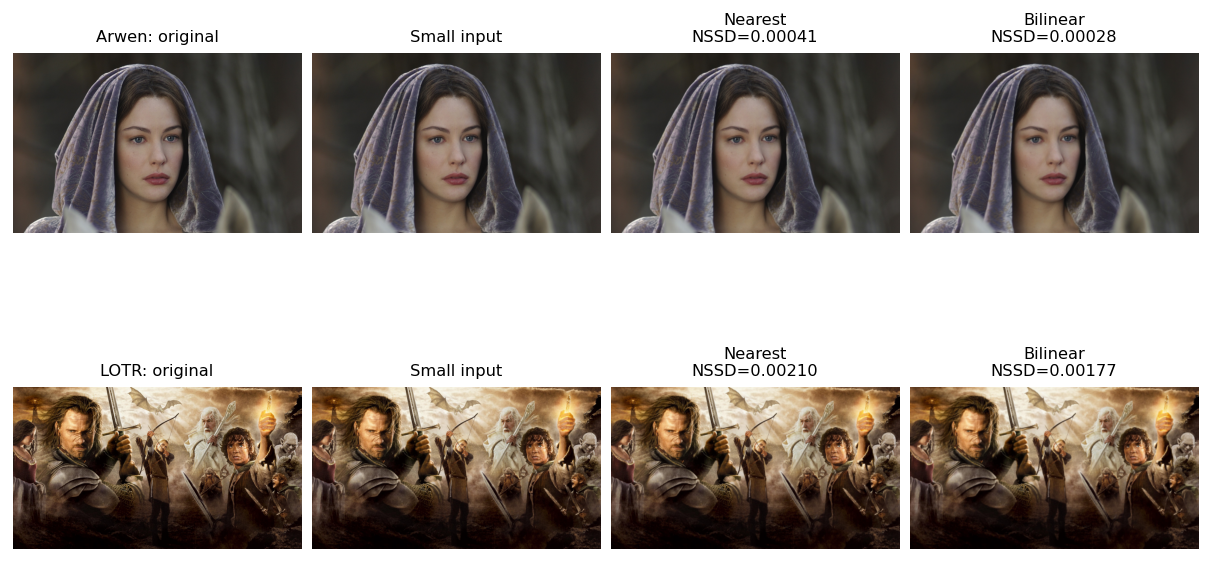

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(9.2, 5.0), constrained_layout=True)
for row, (name, original, small, nearest, bilinear, nn_score, bi_score) in enumerate(q8_results):
    for ax, image, title in zip(axes[row], [original, small, nearest, bilinear],
                                [f"{name}: original", "Small input",
                                 f"Nearest\nNSSD={nn_score:.5f}", f"Bilinear\nNSSD={bi_score:.5f}"]):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
plt.show()

In [29]:
print("Image    Nearest NSSD    Bilinear NSSD")
for name, *_, nn_score, bi_score in q8_results:
    print(f"{name:5s}    {nn_score:.6f}        {bi_score:.6f}")

Image    Nearest NSSD    Bilinear NSSD
Arwen    0.000407        0.000283
LOTR     0.002096        0.001771


**Interpretation and discussion**

I enlarged both small images by a factor of **4** and compared the results with their corresponding large originals. Nearest-neighbour interpolation copies the closest input pixel, which creates visible blocks after enlargement. Bilinear interpolation calculates a weighted average of four neighbouring pixels, producing smoother transitions.

I used $\mathrm{NSSD} = \mathrm{MSE}/255^2$, where MSE is averaged over all pixels and colour channels. A lower value means a closer pixel-by-pixel match to the reference image.

| Image | Nearest-neighbour NSSD | Bilinear NSSD |
| ----- | ---------------------: | ------------: |
| Arwen |               0.000407 |      0.000283 |
| LOTR  |               0.002096 |      0.001771 |

Bilinear interpolation produced a lower error for both images. Together with its smoother appearance, this supports choosing bilinear interpolation for these two photographic examples.

However, enlargement estimates new pixel values from the small image; it cannot fully recover detail lost when the image was reduced. Bilinear interpolation can also soften fine edges because it averages neighbouring values. Therefore, the lower NSSD shows better agreement for these test images, but it does not mean that bilinear interpolation is the best choice for every type of image.


## 9. Foreground enhancement using GrabCut
GrabCut is used to separate the main flower. The extracted background is strongly blurred and recombined with the sharp foreground.

In [30]:
q9_bgr = cv2.imread(str(IMAGE_DIR / "q09_yellow_flower_grabcut.jpeg"))
q9_rgb = cv2.cvtColor(q9_bgr, cv2.COLOR_BGR2RGB)
height9, width9 = q9_bgr.shape[:2]
# Rectangle surrounding the main flower.
rect9 = (10, 125, width9 - 15, 455)
grabcut_mask = np.zeros((height9, width9), dtype=np.uint8)
background_model = np.zeros((1, 65), dtype=np.float64)
foreground_model = np.zeros((1, 65), dtype=np.float64)
cv2.grabCut(q9_bgr, grabcut_mask, rect9, background_model, foreground_model,
            5, cv2.GC_INIT_WITH_RECT)
mask9 = np.where((grabcut_mask == cv2.GC_FGD) |
                 (grabcut_mask == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
foreground9 = cv2.bitwise_and(q9_rgb, q9_rgb, mask=mask9)
background9 = cv2.bitwise_and(q9_rgb, q9_rgb, mask=cv2.bitwise_not(mask9))
blurred_background9 = cv2.GaussianBlur(
    background9,
    (0, 0),
    sigmaX=15,
    sigmaY=15
)
# Keep the blurred layer outside the flower.
blurred_background9 = cv2.bitwise_and(blurred_background9,blurred_background9,mask=cv2.bitwise_not(mask9))
enhanced9 = cv2.add(foreground9, blurred_background9)

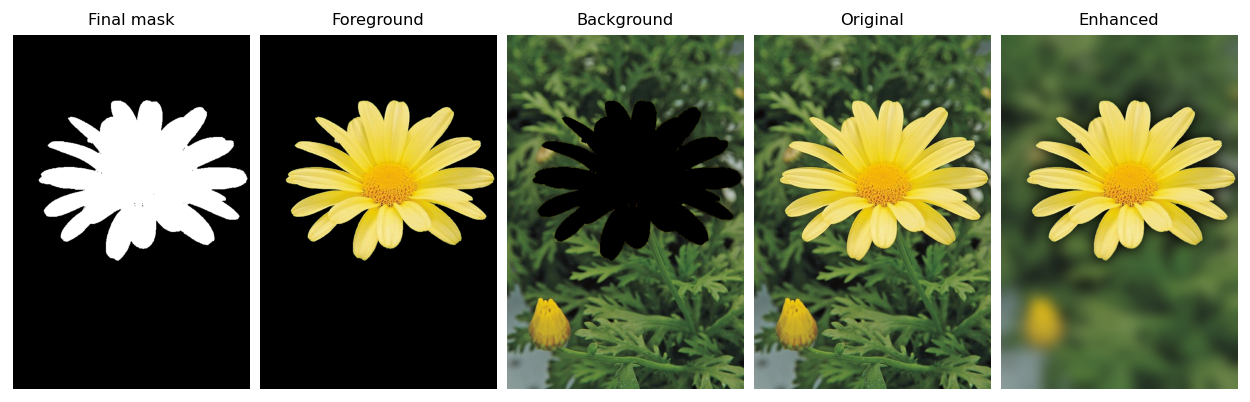

In [31]:
images9 = [mask9, foreground9, background9, q9_rgb, enhanced9]
titles9 = ["Final mask", "Foreground", "Background", "Original", "Enhanced"]
fig, axes = plt.subplots(1, 5, figsize=(9.5, 3.4), constrained_layout=True)
for ax, image, title in zip(axes, images9, titles9):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.show()

**Interpretation and discussion**

GrabCut separated the main yellow flower from the surrounding vegetation. I used the resulting mask to keep the flower sharp while applying strong Gaussian blur to the background with **$\sigma = 15$**. This makes the flower stand out because the surrounding details become less distracting.

The dark region just outside the flower is caused by the way the background was extracted before blurring. Removing the foreground leaves black, zero-valued pixels in the flower’s location. During Gaussian filtering, nearby background pixels are averaged with these zeros. Their intensity decreases, creating a dark halo around the flower.

Placing the sharp foreground back into the image covers the black region inside the flower. However, it does not remove the darkening already introduced into the surrounding background. This explains the effect asked about in Question 9(c).

A possible improvement would be to blur the original image and then combine that blurred image with the sharp foreground. This avoids the black-hole effect, although some flower colour may spread into the blurred background. Another approach would be to calculate the blur using only valid background pixels. These are possible improvements to the method used for the displayed result.


## 10. Bilateral filtering
Gaussian and bilateral smoothing are compared using a $7\times7$ neighbourhood, $\sigma_s=3$, and bilateral range parameter $\sigma_r=40$.

In [32]:
def bilateral_filter(im, kernel_size, sigma_s, sigma_r):
    radius = kernel_size // 2
    padded = cv2.copyMakeBorder(im, radius, radius, radius, radius, cv2.BORDER_REFLECT_101)
    output = np.zeros_like(im, dtype=np.float32)
    yy, xx = np.mgrid[-radius:radius + 1, -radius:radius + 1]
    spatial_weight = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma_s ** 2))
    spatial_weight[xx ** 2 + yy ** 2 > radius ** 2] = 0.0
    for row in range(im.shape[0]):
        for col in range(im.shape[1]):
            patch = padded[row:row + kernel_size, col:col + kernel_size].astype(np.float32)
            centre = im[row, col].astype(np.float32)
            colour_distance = np.sum((patch - centre) ** 2, axis=2)
            range_weight = np.exp(-colour_distance / (2 * sigma_r ** 2))
            weight = spatial_weight * range_weight
            output[row, col] = np.sum(patch * weight[..., None], axis=(0, 1)) / weight.sum()
    return np.clip(np.rint(output), 0, 255).astype(np.uint8)
q10_bgr = cv2.imread(str(IMAGE_DIR / "q10_lake_minaret_bilateral_filter.jpeg"))
q10_rgb = cv2.cvtColor(q10_bgr, cv2.COLOR_BGR2RGB)
kernel_size10, sigma_s10, sigma_r10 = 7, 3.0, 40.0
gaussian10 = cv2.GaussianBlur(q10_rgb, (kernel_size10, kernel_size10), sigma_s10)
opencv_bilateral10 = cv2.bilateralFilter(q10_rgb, kernel_size10, sigma_r10, sigma_s10)
custom_bilateral10 = bilateral_filter(q10_rgb, kernel_size10, sigma_s10, sigma_r10)

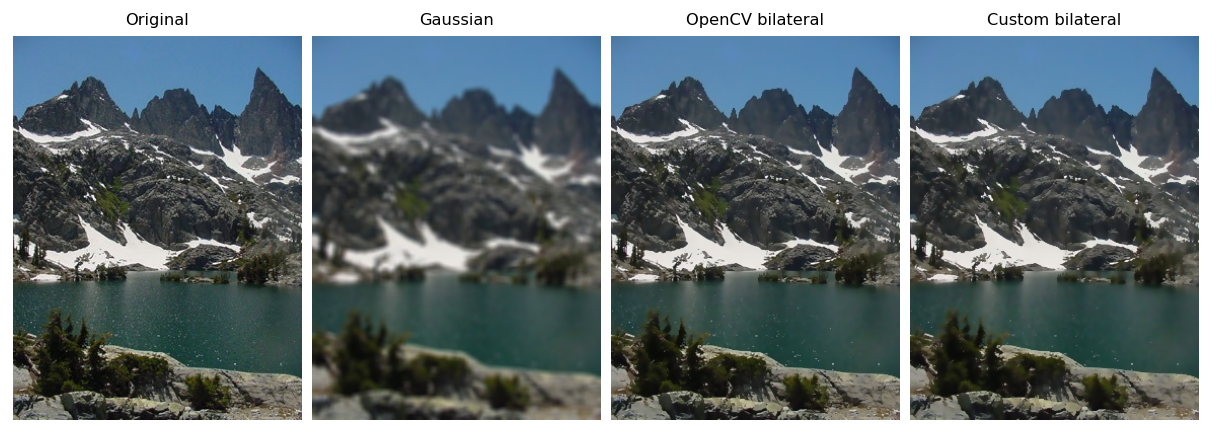

In [33]:
images10 = [q10_rgb, gaussian10, opencv_bilateral10, custom_bilateral10]
titles10 = ["Original", "Gaussian", "OpenCV bilateral", "Custom bilateral"]
fig, axes = plt.subplots(1, 4, figsize=(9.2, 3.2), constrained_layout=True)
for ax, image, title in zip(axes, images10, titles10):
    ax.imshow(image)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.show()

In [34]:
psnr10 = cv2.PSNR(opencv_bilateral10, custom_bilateral10)
mae10 = np.mean(np.abs(opencv_bilateral10.astype(float) - custom_bilateral10.astype(float)))

In [35]:
print(f"Custom vs OpenCV: PSNR = {psnr10:.2f} dB, MAE = {mae10:.2f} intensity levels")

Custom vs OpenCV: PSNR = 38.30 dB, MAE = 1.79 intensity levels


**Interpretation and discussion**

I compared Gaussian smoothing with bilateral filtering using a **$7 \times 7$ neighbourhood**, **$\sigma_s = 3$**, and a bilateral range parameter of **$\sigma_r = 40$**.

Gaussian filtering smooths the image by averaging nearby pixels using spatial distance. It can therefore mix pixels across an edge and soften boundaries. In the result, the mountain and shoreline boundaries become less sharp. Bilateral filtering also considers colour similarity, so neighbouring pixels with very different colours receive smaller weights. This allows it to smooth relatively uniform areas while retaining stronger boundaries.

The custom bilateral result was visually similar to the OpenCV result. Their comparison gave a **PSNR of 38.30 dB** and an **MAE of 1.79 intensity levels**. The MAE means that corresponding colour-channel values differed by about 1.79 levels on average, on a scale from 0 to 255.

The results are not identical partly because of the colour-distance calculation. My implementation adds the squared differences of the colour channels. OpenCV’s standard 8-bit CPU implementation instead squares the sum of their absolute differences. These calculations can give different weights even when the same parameter values are supplied.

Increasing $\sigma_r$ allows pixels with larger colour differences to influence each other, giving stronger smoothing but potentially weakening edges. Increasing $\sigma_s$ gives more influence to farther pixels within the selected neighbourhood.

The comparison shows close agreement between the implementations. However, PSNR and MAE here measure their agreement with each other. They do not establish which output is closest to a noise-free image.
